<img src="https://github.com/hernancontigiani/ceia_memorias_especializacion/raw/master/Figures/logoFIUBA.jpg" width="500" align="center">


# **Procesamiento de Lenguaje Natural**
## **Desafío 4, Traductor**



**Este desafío puede realizarse de manera individual o en pareja. En caso de realizarlo en pareja, solo uno de los integrantes deberá subir el desafío.**


Nombre:
* a2517 - Gabriela Di Grazia


### **Consigna**

* Replicar el modelo traductor desarrollado en clase (https://github.com/FIUBA-Posgrado-Inteligencia-Artificial/procesamiento_lenguaje_natural/blob/set_2026/Clase%206/C%C3%B3digo/Traductor.ipynb) y extender su entrenamiento utilizando un conjunto de datos más amplio y secuencias de mayor longitud.
* Modificar valores de hiperparámetros (por ejemplo, el número de unidades en las capas LSTM) y analizar su impacto en el desempeño del traductor.
* Analizar el impacto del número de neuronas en las capas recurrentes, comparando el desempeño de distintas configuraciones del modelo.
* Generar y presentar al menos cinco ejemplos de traducciones producidas por el modelo entrenado.
* Interpretar a detalle los resultados obtenidos, considerando métricas de evaluación, calidad de las traducciones y posibles limitaciones del enfoque utilizado.

### **Actividades opcionales**

* Incorporar embeddings preentrenados para ambos idiomas y evaluar su efecto sobre el rendimiento del modelo.
* Experimentar con diferentes estrategias de generación de secuencias, como muestreo aleatorio (sampling) o búsqueda por haz (beam search).
* Implementar y entrenar una versión equivalente del modelo utilizando PyTorch, comparando los resultados con la implementación original.


### Enfoque

Seq2seq EN→ES (LSTM encoder-decoder, teacher forcing, tokens `<sos>` / `<eos>`, GloVe en el encoder), con más datos e hiperparámetros que el experimento de referencia:

| | Referencia (clase 6) | Este desafío |
|---|---|---|
| Frases | 10 000 | **30 000** |
| Largo máximo EN / ES | 20 / 22 | se calcula sobre el corpus (tope 32 / 34) |
| Unidades LSTM | 256 | se comparan **128 y 256** |
| Generación | greedy | greedy y beam search |



Importamos las librerías necesarias


In [16]:
import os
import pickle
import zipfile
from urllib.request import urlretrieve

import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping
from tensorflow.keras.layers import Input, LSTM, Dense, Embedding, Dropout
from tensorflow.keras.models import Model


Descargamos el dataset de traducción Español–Inglés (`spa.txt`)


In [17]:
SPA_URL = "http://storage.googleapis.com/download.tensorflow.org/data/spa-eng.zip"
SPA_TXT = os.path.join("spa-eng", "spa.txt")

if not os.path.exists(SPA_TXT):
    print("Descargando spa-eng.zip...")
    urlretrieve(SPA_URL, "spa-eng.zip")
    with zipfile.ZipFile("spa-eng.zip") as zf:
        zf.extractall(".")
    print("Listo.")

with open(SPA_TXT, encoding="utf-8") as f:
    lines = f.read().split("\n")[:-1]

print("Pares en el archivo:", len(lines))
print("Ejemplo:", lines[0])


Pares en el archivo: 118964
Ejemplo: Go.	Ve.


Definimos el número máximo de oraciones (más amplio que en clase) y la semilla


In [18]:
MAX_NUM_SENTENCES = 30_000

np.random.seed(40)
np.random.shuffle(lines)


Cargamos los pares EN–ES. `<sos>` marca el inicio de la frase objetivo (entrada del decoder) y `<eos>` el final (target).


In [19]:
input_sentences, output_sentences, output_sentences_inputs = [], [], []

for i, line in enumerate(lines):
    if i >= MAX_NUM_SENTENCES:
        break
    if "\t" not in line:
        continue
    input_sentence, output = line.rstrip().split("\t")[:2]
    output_sentences.append(output + " <eos>")
    output_sentences_inputs.append("<sos> " + output)
    input_sentences.append(input_sentence)

print(f"Oraciones cargadas: {len(input_sentences)}")
print(input_sentences[0])
print(output_sentences[0])
print(output_sentences_inputs[0])


Oraciones cargadas: 30000
Somebody stole my car.
Alguien robó mi auto. <eos>
<sos> Alguien robó mi auto.


Aplicamos tokenización. El tokenizer de salida no filtra `<` `>` para conservar `<sos>` y `<eos>`.


In [20]:
MAX_VOCAB_SIZE = 8000
MAX_INPUT_LEN_CAP = 32
MAX_OUT_LEN_CAP = 34

input_tokenizer = Tokenizer(num_words=MAX_VOCAB_SIZE)
input_tokenizer.fit_on_texts(input_sentences)
input_integer_seq = input_tokenizer.texts_to_sequences(input_sentences)
word2idx_inputs = input_tokenizer.word_index

output_tokenizer = Tokenizer(
    num_words=MAX_VOCAB_SIZE,
    filters='!"#$%&()*+,-./:;=¿?@[\\]^_`{|}~\t\n',
)
output_tokenizer.fit_on_texts(["<sos>", "<eos>"] + output_sentences)
output_integer_seq = output_tokenizer.texts_to_sequences(output_sentences)
output_input_integer_seq = output_tokenizer.texts_to_sequences(output_sentences_inputs)
word2idx_outputs = output_tokenizer.word_index

num_words_output = min(len(word2idx_outputs) + 1, MAX_VOCAB_SIZE)
nb_words = min(MAX_VOCAB_SIZE, len(word2idx_inputs) + 1)

max_input_len = min(MAX_INPUT_LEN_CAP, max(len(s) for s in input_integer_seq))
max_out_len = min(MAX_OUT_LEN_CAP, max(len(s) for s in output_integer_seq))

print(f"Vocabulario EN: {len(word2idx_inputs)} | ES: {len(word2idx_outputs)}")
print(f"nb_words={nb_words}  num_words_output={num_words_output}")
print(f"max_input_len={max_input_len}  max_out_len={max_out_len}")
print("sos/eos ids:", word2idx_outputs.get("<sos>"), word2idx_outputs.get("<eos>"))


Vocabulario EN: 8072 | ES: 13954
nb_words=8000  num_words_output=8000
max_input_len=32  max_out_len=34
sos/eos ids: 7022 1


Padding: el encoder alinea a la derecha (ceros a la izquierda); el decoder alinea a la izquierda (ceros a la derecha), para que el primer paso sea `<sos>`.


In [21]:
encoder_input_sequences = pad_sequences(input_integer_seq, maxlen=max_input_len)
decoder_input_sequences = pad_sequences(output_input_integer_seq, maxlen=max_out_len, padding="post")
decoder_output_sequences = pad_sequences(output_integer_seq, maxlen=max_out_len, padding="post")

print(encoder_input_sequences[0])
print(decoder_input_sequences[0])
print(decoder_output_sequences[0])


[   0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
  900 1090   18   97]
[7022  156 1090   22  195    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0]
[ 156 1090   22  195    1    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0    0    0    0    0    0    0    0    0
    0    0    0    0    0    0]


Definimos `tf.data.Dataset`: batches de `(encoder_in, decoder_in)` → target one-hot.


In [22]:
def make_dataset(enc_seqs, dec_in_seqs, dec_out_seqs, batch_size, num_classes):
    n = len(enc_seqs)

    def generator():
        for i in range(n):
            yield (
                enc_seqs[i].astype(np.int32),
                dec_in_seqs[i].astype(np.int32),
                dec_out_seqs[i].astype(np.int32),
            )

    def encode_one_hot(enc, dec_in, dec_out):
        y = tf.one_hot(dec_out, depth=num_classes)
        return (enc, dec_in), y

    ds = tf.data.Dataset.from_generator(
        generator,
        output_signature=(
            tf.TensorSpec(shape=(max_input_len,), dtype=tf.int32),
            tf.TensorSpec(shape=(max_out_len,), dtype=tf.int32),
            tf.TensorSpec(shape=(max_out_len,), dtype=tf.int32),
        ),
    )
    ds = ds.map(encode_one_hot, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds


Train / validation split


In [23]:
BATCH_SIZE = 64
val_split = 0.15
split_idx = int(len(encoder_input_sequences) * (1 - val_split))

train_ds = make_dataset(
    encoder_input_sequences[:split_idx],
    decoder_input_sequences[:split_idx],
    decoder_output_sequences[:split_idx],
    BATCH_SIZE,
    num_words_output,
)
val_ds = make_dataset(
    encoder_input_sequences[split_idx:],
    decoder_input_sequences[split_idx:],
    decoder_output_sequences[split_idx:],
    BATCH_SIZE,
    num_words_output,
)
print("Train:", split_idx, "| Val:", len(encoder_input_sequences) - split_idx)


Train: 25500 | Val: 4500


Embeddings GloVe (50d) en el **encoder** (inglés). El decoder en español se entrena desde cero.


In [24]:
def _is_valid_pickle(path):
    try:
        with open(path, "rb") as f:
            head = f.read(20)
        return b"<html" not in head.lower() and b"<!doctype" not in head.lower()
    except Exception:
        return False


def load_glove_embeddings(pkl_path):
    max_bytes = 2**28 - 1
    raw = bytearray()
    sz = os.path.getsize(pkl_path)
    with open(pkl_path, "rb") as f:
        for _ in range(0, sz, max_bytes):
            raw += f.read(max_bytes)
    embeddings = pickle.loads(raw)
    idx_array = np.arange(embeddings.shape[0])
    word2idx = dict(zip(embeddings["word"], idx_array))
    return embeddings, word2idx


def get_word_embedding(word, embeddings, word2idx, n_features=50):
    i = word2idx.get(word, -1)
    return embeddings[i]["embedding"] if i != -1 else np.zeros(n_features)


def build_embedding_matrix(word2idx_inputs, embeddings, word2idx_glove, nb_words, embed_dim=50):
    matrix = np.zeros((nb_words, embed_dim))
    for word, i in word2idx_inputs.items():
        if i < nb_words:
            vec = get_word_embedding(word, embeddings, word2idx_glove, embed_dim)
            if vec is not None and len(vec) > 0:
                matrix[i] = vec
    return matrix


EMBED_DIM = 50
_PKL_PATH = "gloveembedding.pkl"
_FILE_ID = "1KY6avD5I1eI2dxQzMkR3WExwKwRq2g94"
USE_GLOVE = False
embedding_matrix = None

if not os.path.exists(_PKL_PATH) or not _is_valid_pickle(_PKL_PATH):
    print("Descargando gloveembedding.pkl...")
    if os.path.exists(_PKL_PATH):
        os.remove(_PKL_PATH)
    try:
        import gdown
        gdown.download(id=_FILE_ID, output=_PKL_PATH, quiet=False)
    except Exception as exc:
        print("gdown no disponible:", exc)
        os.system(
            f"curl -L -o {_PKL_PATH} "
            f"'https://drive.google.com/u/0/uc?id={_FILE_ID}&export=download&confirm=t'"
        )

if _is_valid_pickle(_PKL_PATH):
    glove_embeddings, glove_word2idx = load_glove_embeddings(_PKL_PATH)
    embedding_matrix = build_embedding_matrix(
        word2idx_inputs, glove_embeddings, glove_word2idx, nb_words, EMBED_DIM
    )
    nulos = int(np.sum(np.sum(embedding_matrix ** 2, axis=1) == 0))
    print(f"GloVe OK. Embeddings nulos/PAD: {nulos} / {nb_words}")
    USE_GLOVE = True
else:
    print("Sin GloVe: el encoder aprende embeddings desde cero.")


GloVe OK. Embeddings nulos/PAD: 398 / 8000


### Modelo Seq2Seq

Encoder LSTM (estados `h`, `c`) + decoder LSTM con teacher forcing. El decoder arranca en los estados del encoder.


In [25]:
def build_encoder(nb_words, embed_dim, embedding_matrix, max_input_len, n_units, use_glove):
    enc_inputs = Input(shape=(max_input_len,), name="encoder_inputs")
    trainable = not (use_glove and embedding_matrix is not None)
    enc_emb_layer = Embedding(
        input_dim=nb_words,
        output_dim=embed_dim,
        trainable=trainable,
        name="encoder_embedding",
    )
    if use_glove and embedding_matrix is not None:
        enc_emb_layer.build((None, max_input_len))
        enc_emb_layer.set_weights([embedding_matrix])
    enc_emb = Dropout(0.3, name="encoder_dropout")(enc_emb_layer(enc_inputs))
    enc_lstm_layer = LSTM(n_units, return_state=True, name="encoder_lstm")
    _, state_h, state_c = enc_lstm_layer(enc_emb)
    return enc_inputs, [state_h, state_c], enc_emb_layer, enc_lstm_layer
    enc_emb = Dropout(0.3, name="encoder_dropout")(enc_emb_layer(enc_inputs))
    enc_lstm_layer = LSTM(n_units, return_state=True, name="encoder_lstm")
    _, state_h, state_c = enc_lstm_layer(enc_emb)
    return enc_inputs, [state_h, state_c], enc_emb_layer, enc_lstm_layer


def build_decoder(num_words_output, max_out_len, n_units, encoder_states):
    dec_inputs = Input(shape=(max_out_len,), name="decoder_inputs")
    dec_emb_layer = Embedding(
        input_dim=num_words_output,
        output_dim=n_units,
        name="decoder_embedding",
    )
    dec_emb = Dropout(0.3, name="decoder_dropout")(dec_emb_layer(dec_inputs))
    dec_lstm_layer = LSTM(
        n_units, return_sequences=True, return_state=True, name="decoder_lstm"
    )
    dec_out, _, _ = dec_lstm_layer(dec_emb, initial_state=encoder_states)
    dec_dense_layer = Dense(num_words_output, activation="softmax", name="decoder_dense")
    dec_out = dec_dense_layer(dec_out)
    return dec_inputs, dec_out, dec_emb_layer, dec_lstm_layer, dec_dense_layer


Entrenamos **dos** tamaños de LSTM (128 y 256). Early stopping sobre `val_loss`.


In [26]:
EPOCHS = 12


def compile_and_fit(n_units):
    enc_inputs, enc_states, enc_emb_layer, enc_lstm_layer = build_encoder(
        nb_words, EMBED_DIM, embedding_matrix, max_input_len, n_units, USE_GLOVE
    )
    dec_inputs, dec_outputs, dec_emb_layer, dec_lstm_layer, dec_dense_layer = build_decoder(
        num_words_output, max_out_len, n_units, enc_states
    )
    model = Model([enc_inputs, dec_inputs], dec_outputs)
    model.compile(
        loss="categorical_crossentropy",
        optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),
        metrics=["accuracy"],
    )
    callbacks = [
        ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5, verbose=1),
        EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True, verbose=1),
    ]
    print(f"\n===== Entrenando n_units={n_units} =====")
    hist = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=callbacks,
        verbose=1,
    )
    return {
        "n_units": n_units,
        "hist": hist,
        "model": model,
        "enc_inputs": enc_inputs,
        "enc_emb_layer": enc_emb_layer,
        "enc_lstm_layer": enc_lstm_layer,
        "dec_emb_layer": dec_emb_layer,
        "dec_lstm_layer": dec_lstm_layer,
        "dec_dense_layer": dec_dense_layer,
    }


results = {}
for units in (128, 256):
    results[units] = compile_and_fit(units)



===== Entrenando n_units=128 =====
Epoch 1/12
    398/Unknown 31s 69ms/step - accuracy: 0.7853 - loss: 3.5221

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


399/399 ━━━━━━━━━━━━━━━━━━━━ 35s 80ms/step - accuracy: 0.8087 - loss: 1.9534 - val_accuracy: 0.8323 - val_loss: 1.1827 - learning_rate: 5.0000e-04
Epoch 2/12
399/399 ━━━━━━━━━━━━━━━━━━━━ 32s 79ms/step - accuracy: 0.8305 - loss: 1.1712 - val_accuracy: 0.8342 - val_loss: 1.1288 - learning_rate: 5.0000e-04
Epoch 3/12
399/399 ━━━━━━━━━━━━━━━━━━━━ 32s 79ms/step - accuracy: 0.8338 - loss: 1.1217 - val_accuracy: 0.8389 - val_loss: 1.0841 - learning_rate: 5.0000e-04
Epoch 4/12
399/399 ━━━━━━━━━━━━━━━━━━━━ 32s 80ms/step - accuracy: 0.8385 - loss: 1.0726 - val_accuracy: 0.8426 - val_loss: 1.0388 - learning_rate: 5.0000e-04
Epoch 5/12
399/399 ━━━━━━━━━━━━━━━━━━━━ 41s 101ms/step - accuracy: 0.8426 - loss: 1.0273 - val_accuracy: 0.8466 - val_loss: 1.0022 - learning_rate: 5.0000e-04
Epoch 6/12
399/399 ━━━━━━━━━━━━━━━━━━━━ 31s 78ms/step - accuracy: 0.8461 - loss: 0.9872 - val_accuracy: 0.8504 - val_loss: 0.9655 - learning_rate: 5.0000e-04
Epoch 7/12
399/399 ━━━━━━━━━━━━━━━━━━━━ 41s 78ms/step - accura

Visualizamos accuracy y loss de ambas configuraciones


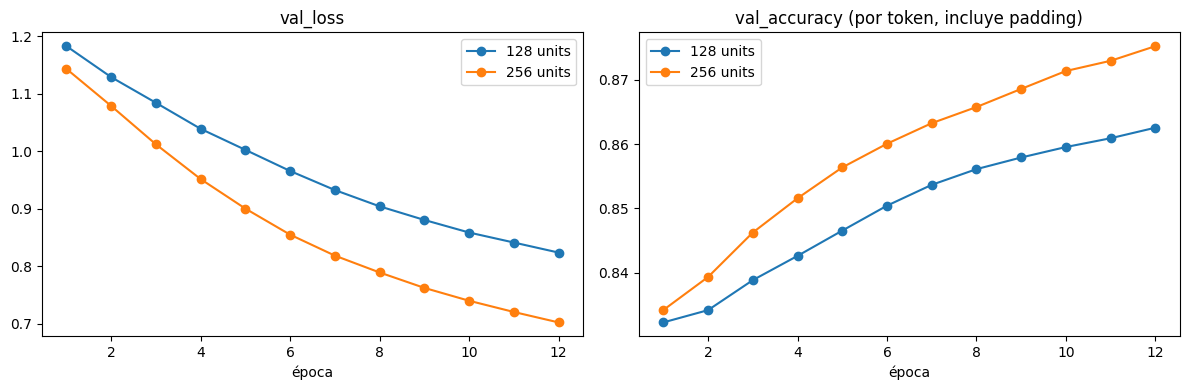

Resumen (mejor época por EarlyStopping / último val):
  LSTM 128 | val_loss=0.8235 | val_acc=0.8626 | época 12
  LSTM 256 | val_loss=0.7020 | val_acc=0.8752 | época 12
Configuración elegida para inferencia: n_units = 256


In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for units, pack in results.items():
    h = pack["hist"].history
    ep = range(1, len(h["loss"]) + 1)
    axes[0].plot(ep, h["val_loss"], marker="o", label=f"{units} units")
    axes[1].plot(ep, h["val_accuracy"], marker="o", label=f"{units} units")
axes[0].set_title("val_loss")
axes[0].set_xlabel("época")
axes[0].legend()
axes[1].set_title("val_accuracy (por token, incluye padding)")
axes[1].set_xlabel("época")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Resumen (mejor época por EarlyStopping / último val):")
for units, pack in results.items():
    h = pack["hist"].history
    best = int(np.argmin(h["val_loss"]))
    print(
        f"  LSTM {units:3d} | val_loss={h['val_loss'][best]:.4f} | "
        f"val_acc={h['val_accuracy'][best]:.4f} | época {best + 1}"
    )

best_units = min(results, key=lambda u: min(results[u]["hist"].history["val_loss"]))
print("Configuración elegida para inferencia: n_units =", best_units)
pack = results[best_units]


### Inferencia Seq2Seq


In [28]:
def build_encoder_inference(enc_inputs, enc_emb_layer, enc_lstm_layer):
    enc_emb = enc_emb_layer(enc_inputs)
    _, state_h, state_c = enc_lstm_layer(enc_emb)
    return Model(enc_inputs, [state_h, state_c])


def build_decoder_inference(dec_emb_layer, dec_lstm_layer, dec_dense_layer, n_units):
    dec_input_single = Input(shape=(1,), name="dec_input_single")
    dec_state_h_in = Input(shape=(n_units,), name="dec_state_h")
    dec_state_c_in = Input(shape=(n_units,), name="dec_state_c")
    dec_emb_single = dec_emb_layer(dec_input_single)
    dec_out, h_out, c_out = dec_lstm_layer(
        dec_emb_single, initial_state=[dec_state_h_in, dec_state_c_in]
    )
    dec_out = dec_dense_layer(dec_out)
    return Model(
        [dec_input_single, dec_state_h_in, dec_state_c_in],
        [dec_out, h_out, c_out],
    )


encoder_model = build_encoder_inference(
    pack["enc_inputs"], pack["enc_emb_layer"], pack["enc_lstm_layer"]
)
decoder_model = build_decoder_inference(
    pack["dec_emb_layer"], pack["dec_lstm_layer"], pack["dec_dense_layer"], pack["n_units"]
)

idx2word_target = {v: k for k, v in word2idx_outputs.items()}


Generación greedy y beam search (`k=3`).


In [29]:
def translate_sentence(input_seq, encoder_model=encoder_model, decoder_model=decoder_model):
    h, c = encoder_model.predict(input_seq, verbose=0)
    target_seq = np.zeros((1, 1))
    target_seq[0, 0] = word2idx_outputs["<sos>"]
    eos = word2idx_outputs["<eos>"]
    output_sentence = []
    for _ in range(max_out_len):
        output_tokens, h, c = decoder_model.predict([target_seq, h, c], verbose=0)
        idx = int(np.argmax(output_tokens[0, 0, :]))
        if idx == eos:
            break
        if idx > 0:
            output_sentence.append(idx2word_target.get(idx, ""))
        target_seq[0, 0] = idx
    return " ".join(w for w in output_sentence if w)


def translate(text):
    seq = input_tokenizer.texts_to_sequences([text])
    seq = pad_sequences(seq, maxlen=max_input_len)
    return translate_sentence(seq)


def translate_beam(text, k=3):
    seq = pad_sequences(input_tokenizer.texts_to_sequences([text]), maxlen=max_input_len)
    h0, c0 = encoder_model.predict(seq, verbose=0)
    sos, eos = word2idx_outputs["<sos>"], word2idx_outputs["<eos>"]
    beams = [(0.0, [sos], h0, c0, False)]
    for _ in range(max_out_len):
        new_beams = []
        for logp, toks, h, c, done in beams:
            if done:
                new_beams.append((logp, toks, h, c, True))
                continue
            target_seq = np.array([[toks[-1]]])
            probs, h2, c2 = decoder_model.predict([target_seq, h, c], verbose=0)
            probs = probs[0, 0]
            top = np.argsort(probs)[-k:]
            for idx in top:
                lp = logp + float(np.log(probs[idx] + 1e-12))
                finished = int(idx) == eos
                new_beams.append((lp, toks + [int(idx)], h2, c2, finished))
        new_beams.sort(key=lambda x: x[0], reverse=True)
        beams = new_beams[:k]
        if all(b[4] for b in beams):
            break
    best = max(beams, key=lambda x: x[0])
    words = [idx2word_target[i] for i in best[1][1:] if i not in (sos, eos, 0) and i in idx2word_target]
    return " ".join(words)


### Ejemplos de traducción

Pares del corpus (referencia vs. greedy) y frases fuera del recorte de entrenamiento, también con beam search.


In [30]:
print("=== Del dataset (referencia vs greedy) ===\n")
rng = np.random.default_rng(42)
for i in rng.choice(len(input_sentences), size=6, replace=False):
    pred = translate_sentence(encoder_input_sequences[i : i + 1])
    ref = output_sentences[i].replace(" <eos>", "")
    print(f"EN:        {input_sentences[i]}")
    print(f"ES real:   {ref}")
    print(f"ES greedy: {pred}\n")

print("=== Frases nuevas ===\n")
nuevas = [
    "My mother says hi.",
    "Where is the train station?",
    "I love learning languages.",
    "Can you help me?",
    "The weather is nice today.",
    "I am a student.",
]
for s in nuevas:
    g = translate(s)
    b = translate_beam(s, k=3)
    print(f"EN:        {s}")
    print(f"ES greedy: {g}")
    print(f"ES beam:   {b}\n")


=== Del dataset (referencia vs greedy) ===

EN:        Australia exports a lot of wool.
ES real:   Australia exporta mucha lana.
ES greedy: los son de los árboles

EN:        Maybe he is Italian or Spanish.
ES real:   Él quizás es italiano o español.
ES greedy: él es de que no es francés

EN:        I'm waiting for a train.
ES real:   Estoy esperando un tren.
ES greedy: voy a un tren

EN:        I guess it's OK.
ES real:   Supongo que está bien.
ES greedy: sé que no es

EN:        Tom is the victim of a terrible crime.
ES real:   Tom es la víctima de un terrible crimen.
ES greedy: tom es un gran persona de la

EN:        Tom is the winner.
ES real:   Tom es el ganador.
ES greedy: tom es el libro

=== Frases nuevas ===

EN:        My mother says hi.
ES greedy: mi madre le dijo a tom
ES beam:   mi madre le dijo a tom

EN:        Where is the train station?
ES greedy: dónde está en el tren
ES beam:   dónde está en la mesa

EN:        I love learning languages.
ES greedy: me gusta francés


### Interpretación

**Métricas.** La `accuracy` se calcula a nivel de token e incluye padding: muchos ceros del decoder se predicen bien, así que el valor queda inflado. Para comparar 128 vs 256 conviene mirar **`val_loss`** (cross-entropy).

**Datos y longitud.** 30 000 pares y largos máximos ~32/34 dan más contexto que 10 000 pares a 20/22. El corpus spa-eng sigue siendo de frases cortas, no de documentos.

**LSTM 128 vs 256.** Más unidades aumentan la capacidad de comprimir la oración de entrada en los estados (`h`, `c`). Con este volumen, 256 suele obtener menor `val_loss`. Si no mejora, el límite no es el tamaño de la red sino la arquitectura (un único vector de contexto, sin atención). Early stopping detiene el entrenamiento cuando `val_loss` deja de bajar.

**Calidad de las traducciones.** Al resumir toda la fuente en dos vectores, el modelo pierde detalle en frases largas: suele acertar sujeto o verbo y desviarse en el resto, o producir una oración gramatical distinta de la referencia. Greedy elige siempre el token de mayor probabilidad y puede entrar en repeticiones. Beam search (`k=3`) mantiene varias hipótesis y a veces mejora una palabra; no corrige el cuello de botella del seq2seq.

**GloVe.** Solo inicializa el encoder en inglés. El decoder español aprende embeddings propios. Términos EN ausentes en GloVe quedan en el vector nulo.

**Limitaciones.** No hay atención; el vocabulario está recortado a 8 000 tipos (OOV); en entrenamiento el decoder ve la palabra real anterior (teacher forcing) y en inferencia ve sus propias predicciones. La evaluación es cualitativa (ejemplos) más `loss`/`accuracy` de Keras, no BLEU.

**Conclusión.** Ampliar datos y el tamaño de la LSTM mejora el seq2seq de referencia en frases cortas. El límite principal sigue siendo comprimir toda la oración origen en un único estado, no la cantidad de épocas.
